In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
client=pd.read_csv("client_data.csv")
price=pd.read_csv("price_data.csv")

In [3]:
client.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,t,0.00,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,f,0.00,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,f,0.00,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,f,0.00,30.22,30.22,1,25.46,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.200,0
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,f,52.32,44.91,44.91,1,47.98,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,19.800,0


In [4]:
price.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [5]:
price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  193002 non-null  object 
 1   price_date          193002 non-null  object 
 2   price_off_peak_var  193002 non-null  float64
 3   price_peak_var      193002 non-null  float64
 4   price_mid_peak_var  193002 non-null  float64
 5   price_off_peak_fix  193002 non-null  float64
 6   price_peak_fix      193002 non-null  float64
 7   price_mid_peak_fix  193002 non-null  float64
dtypes: float64(6), object(2)
memory usage: 11.8+ MB


In [6]:
client.count()

id                                14606
channel_sales                     14606
cons_12m                          14606
cons_gas_12m                      14606
cons_last_month                   14606
date_activ                        14606
date_end                          14606
date_modif_prod                   14606
date_renewal                      14606
forecast_cons_12m                 14606
forecast_cons_year                14606
forecast_discount_energy          14606
forecast_meter_rent_12m           14606
forecast_price_energy_off_peak    14606
forecast_price_energy_peak        14606
forecast_price_pow_off_peak       14606
has_gas                           14606
imp_cons                          14606
margin_gross_pow_ele              14606
margin_net_pow_ele                14606
nb_prod_act                       14606
net_margin                        14606
num_years_antig                   14606
origin_up                         14606
pow_max                           14606


In [7]:
client["id"].nunique()

14606

In [8]:
price.count()

id                    193002
price_date            193002
price_off_peak_var    193002
price_peak_var        193002
price_mid_peak_var    193002
price_off_peak_fix    193002
price_peak_fix        193002
price_mid_peak_fix    193002
dtype: int64

In [9]:
price.groupby("id")

In [10]:
def stack_architect(data,title):
    ax=data.plot(kind="bar",stacked=True,title=title)
    annotate(ax)
    plt.legend(["Retention","Churn"],loc="upper right")
    plt.title(title)
    plt.ylabel("company base percentage")
    plt.show()

def annotate(ax,padding=0.99):
    for k in ax.patches:
        value=str(round(k.get_height(),1))
        if value=="0.0": continue
        ax.annotate(value,((k.get_x()+k.get_width()/2)*padding-0.05,(k.get_y()+k.get_height()/2)),color="white")


CHURN

In [11]:
churn=client[["id","churn"]]
churn.columns=["company","churn"]
churn_total=churn.groupby("churn").count()
churn_perc=churn_total/churn_total.sum()*100
churn_perc

,company
churn,
0,90.284814
1,9.715186


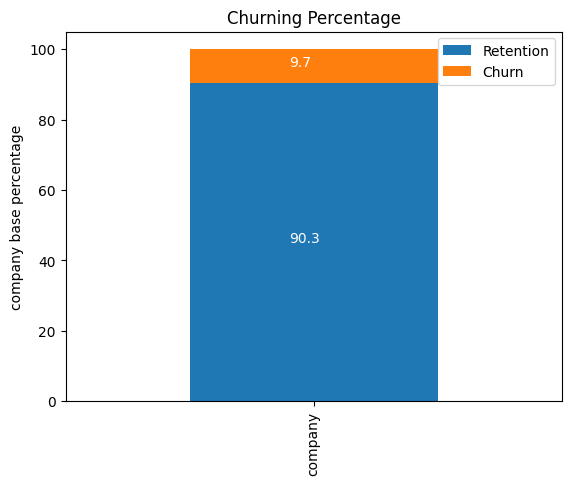

In [12]:
stack_architect(churn_perc.transpose(),"Churning Percentage")

In [13]:
client.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent_12m         

In [14]:
channel=client[["id","channel_sales","churn"]]
channel=channel.groupby(["channel_sales","churn"]).id.count()
channel=channel.unstack(level=1).fillna(0)
print(channel.head())
channel_perc=(channel.div(channel.sum(axis=1),axis=0)*100).sort_values(by=1,ascending=False)
channel_perc.head()

churn                                  0      1
channel_sales                                  
MISSING                           3442.0  283.0
epumfxlbckeskwekxbiuasklxalciiuu     3.0    0.0
ewpakwlliwisiwduibdlfmalxowmwpci   818.0   75.0
fixdbufsefwooaasfcxdxadsiekoceaa     2.0    0.0
foosdfpfkusacimwkcsosbicdxkicaua  5934.0  820.0


churn,0,1
channel_sales,,
foosdfpfkusacimwkcsosbicdxkicaua,87.859046,12.140954
usilxuppasemubllopkaafesmlibmsdf,89.963636,10.036364
ewpakwlliwisiwduibdlfmalxowmwpci,91.601344,8.398656
MISSING,92.402685,7.597315
lmkebamcaaclubfxadlmueccxoimlema,94.411286,5.588714


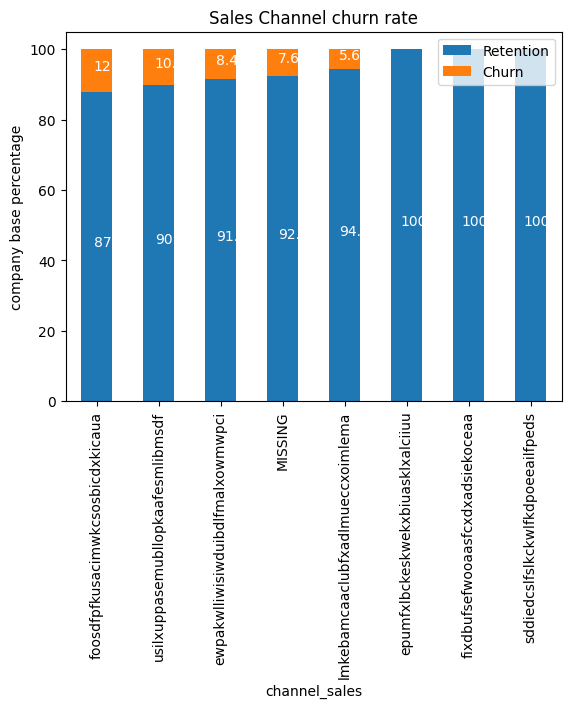

In [15]:
stack_architect(channel_perc,"Sales Channel churn rate")

CONSUMPTION

In [16]:
consume=client[["id","cons_12m","cons_gas_12m","cons_last_month","has_gas","imp_cons","pow_max","churn"]]
consume.head()

,id,cons_12m,cons_gas_12m,cons_last_month,has_gas,imp_cons,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,0,54946,0,t,0.00,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,4660,0,0,f,0.00,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,544,0,0,f,0.00,13.856,0
3,bba03439a292a1e166f80264c16191cb,1584,0,0,f,0.00,13.200,0
4,149d57cf92fc41cf94415803a877cb4b,4425,0,526,f,52.32,19.800,0


In [17]:
def hist_plot(df,column,ax):

    temp_data=pd.DataFrame({"Retention":df[df["churn"]==0][column],"Churn":df[df["churn"]==1][column]})
    temp_data[["Retention","Churn"]].plot(kind="hist",stacked=True,ax=ax,bins=50)
    ax.set_xlabel(column)
    ax.ticklabel_format(style='plain',axis='x')
    

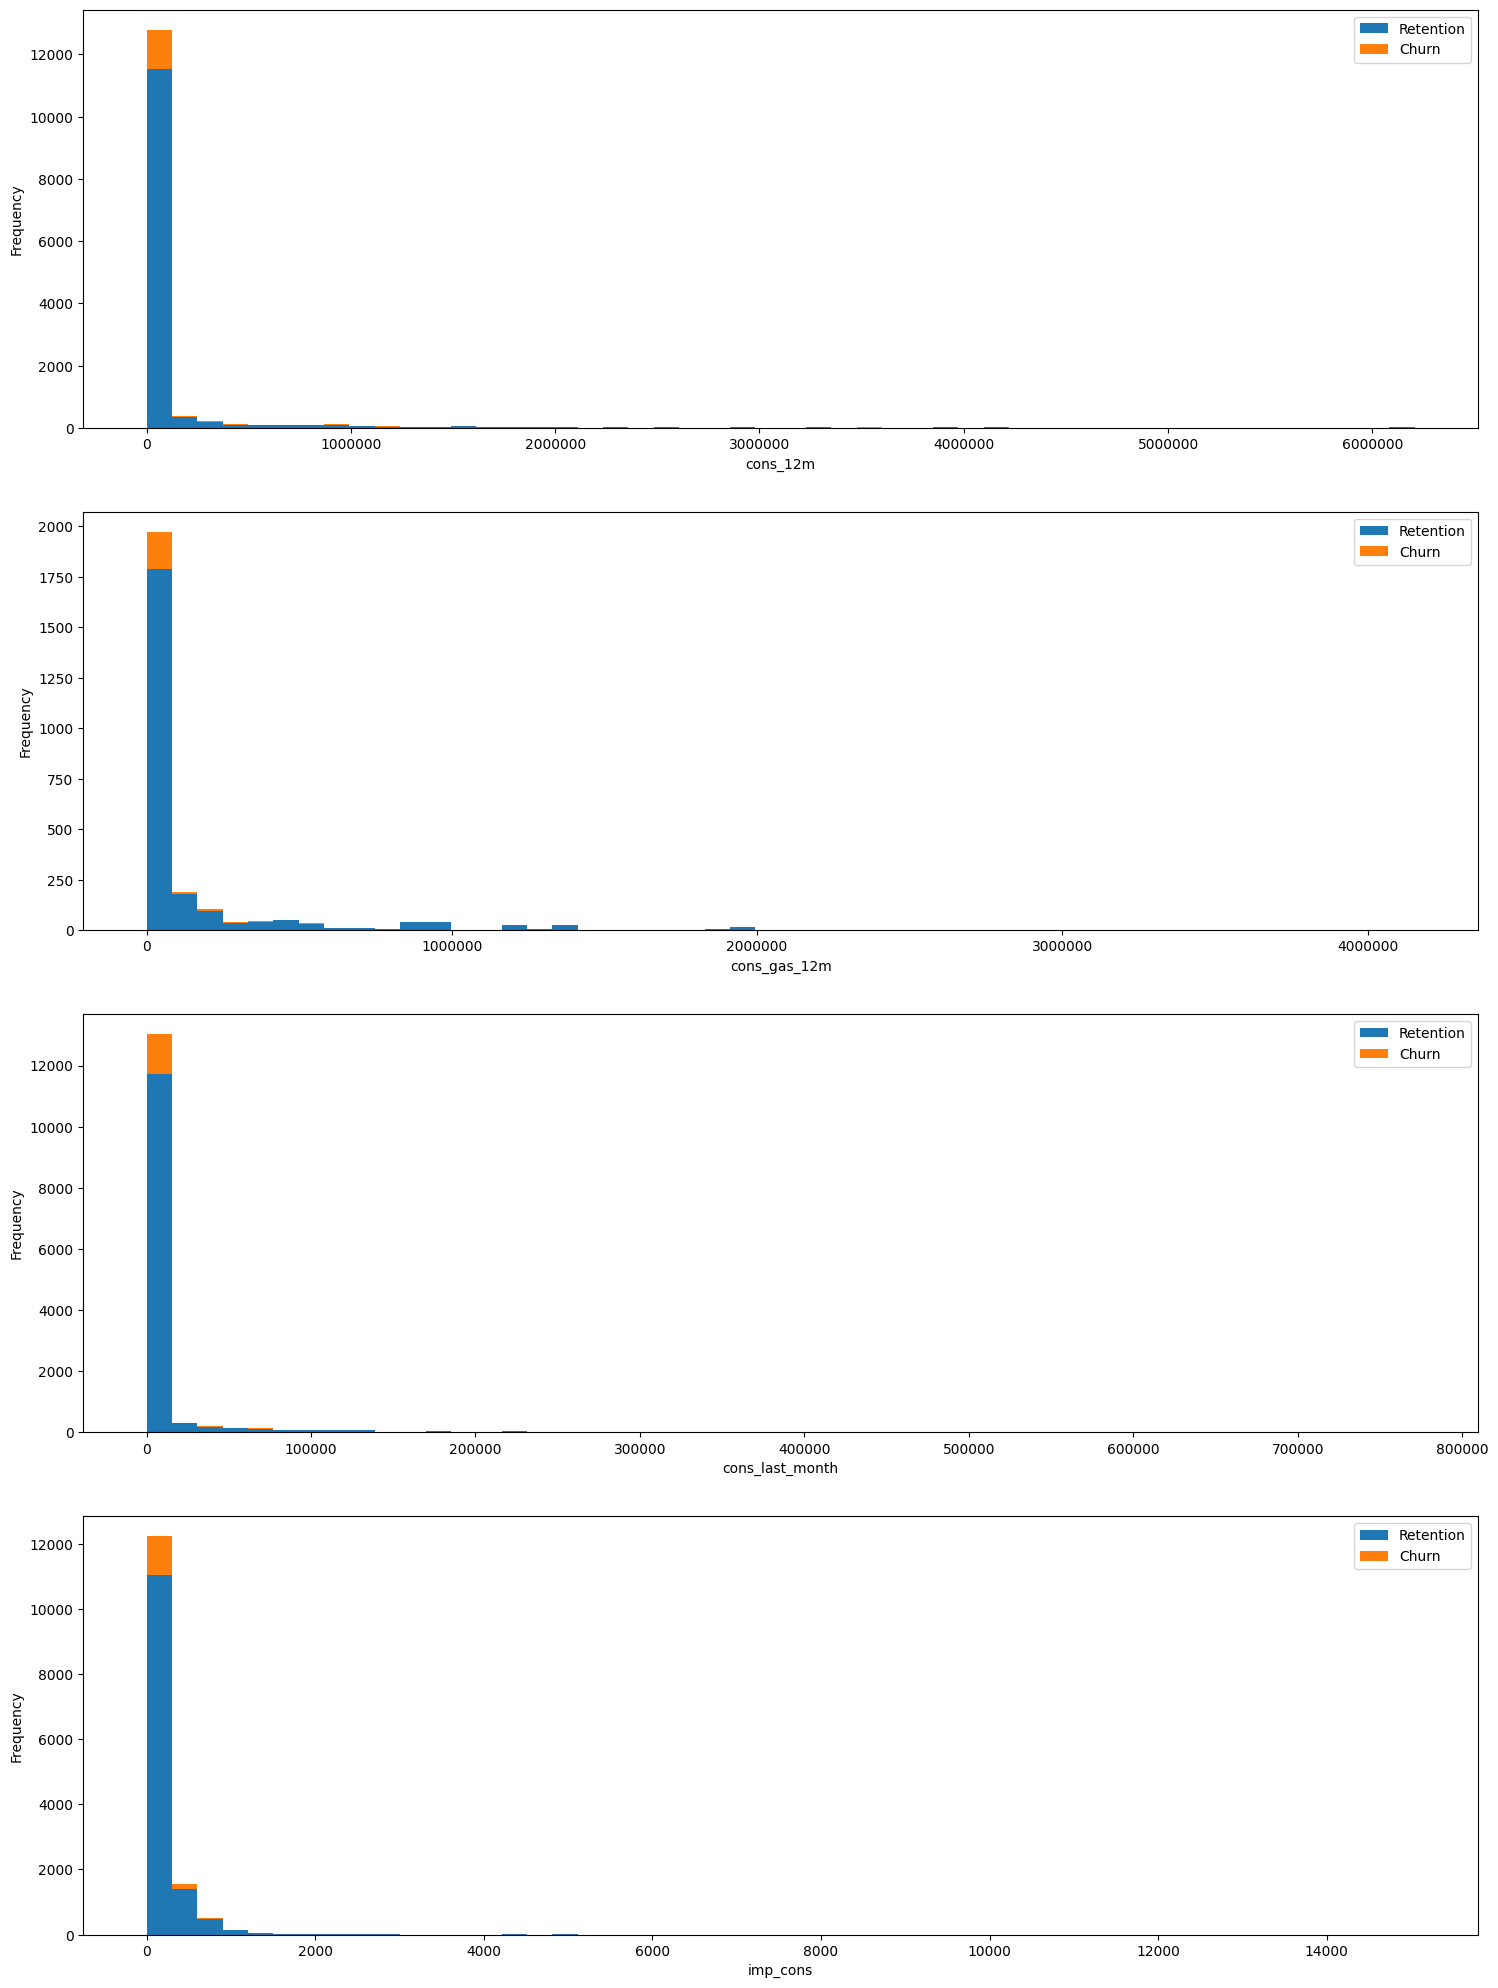

In [18]:
fig,ax=plt.subplots(nrows=4,figsize=(18,25))

hist_plot(consume,"cons_12m",ax[0])
hist_plot(consume[consume["has_gas"]=="t"],"cons_gas_12m",ax[1])
hist_plot(consume,"cons_last_month",ax[2])
hist_plot(consume,"imp_cons",ax[3])

<Axes: ylabel='imp_cons'>

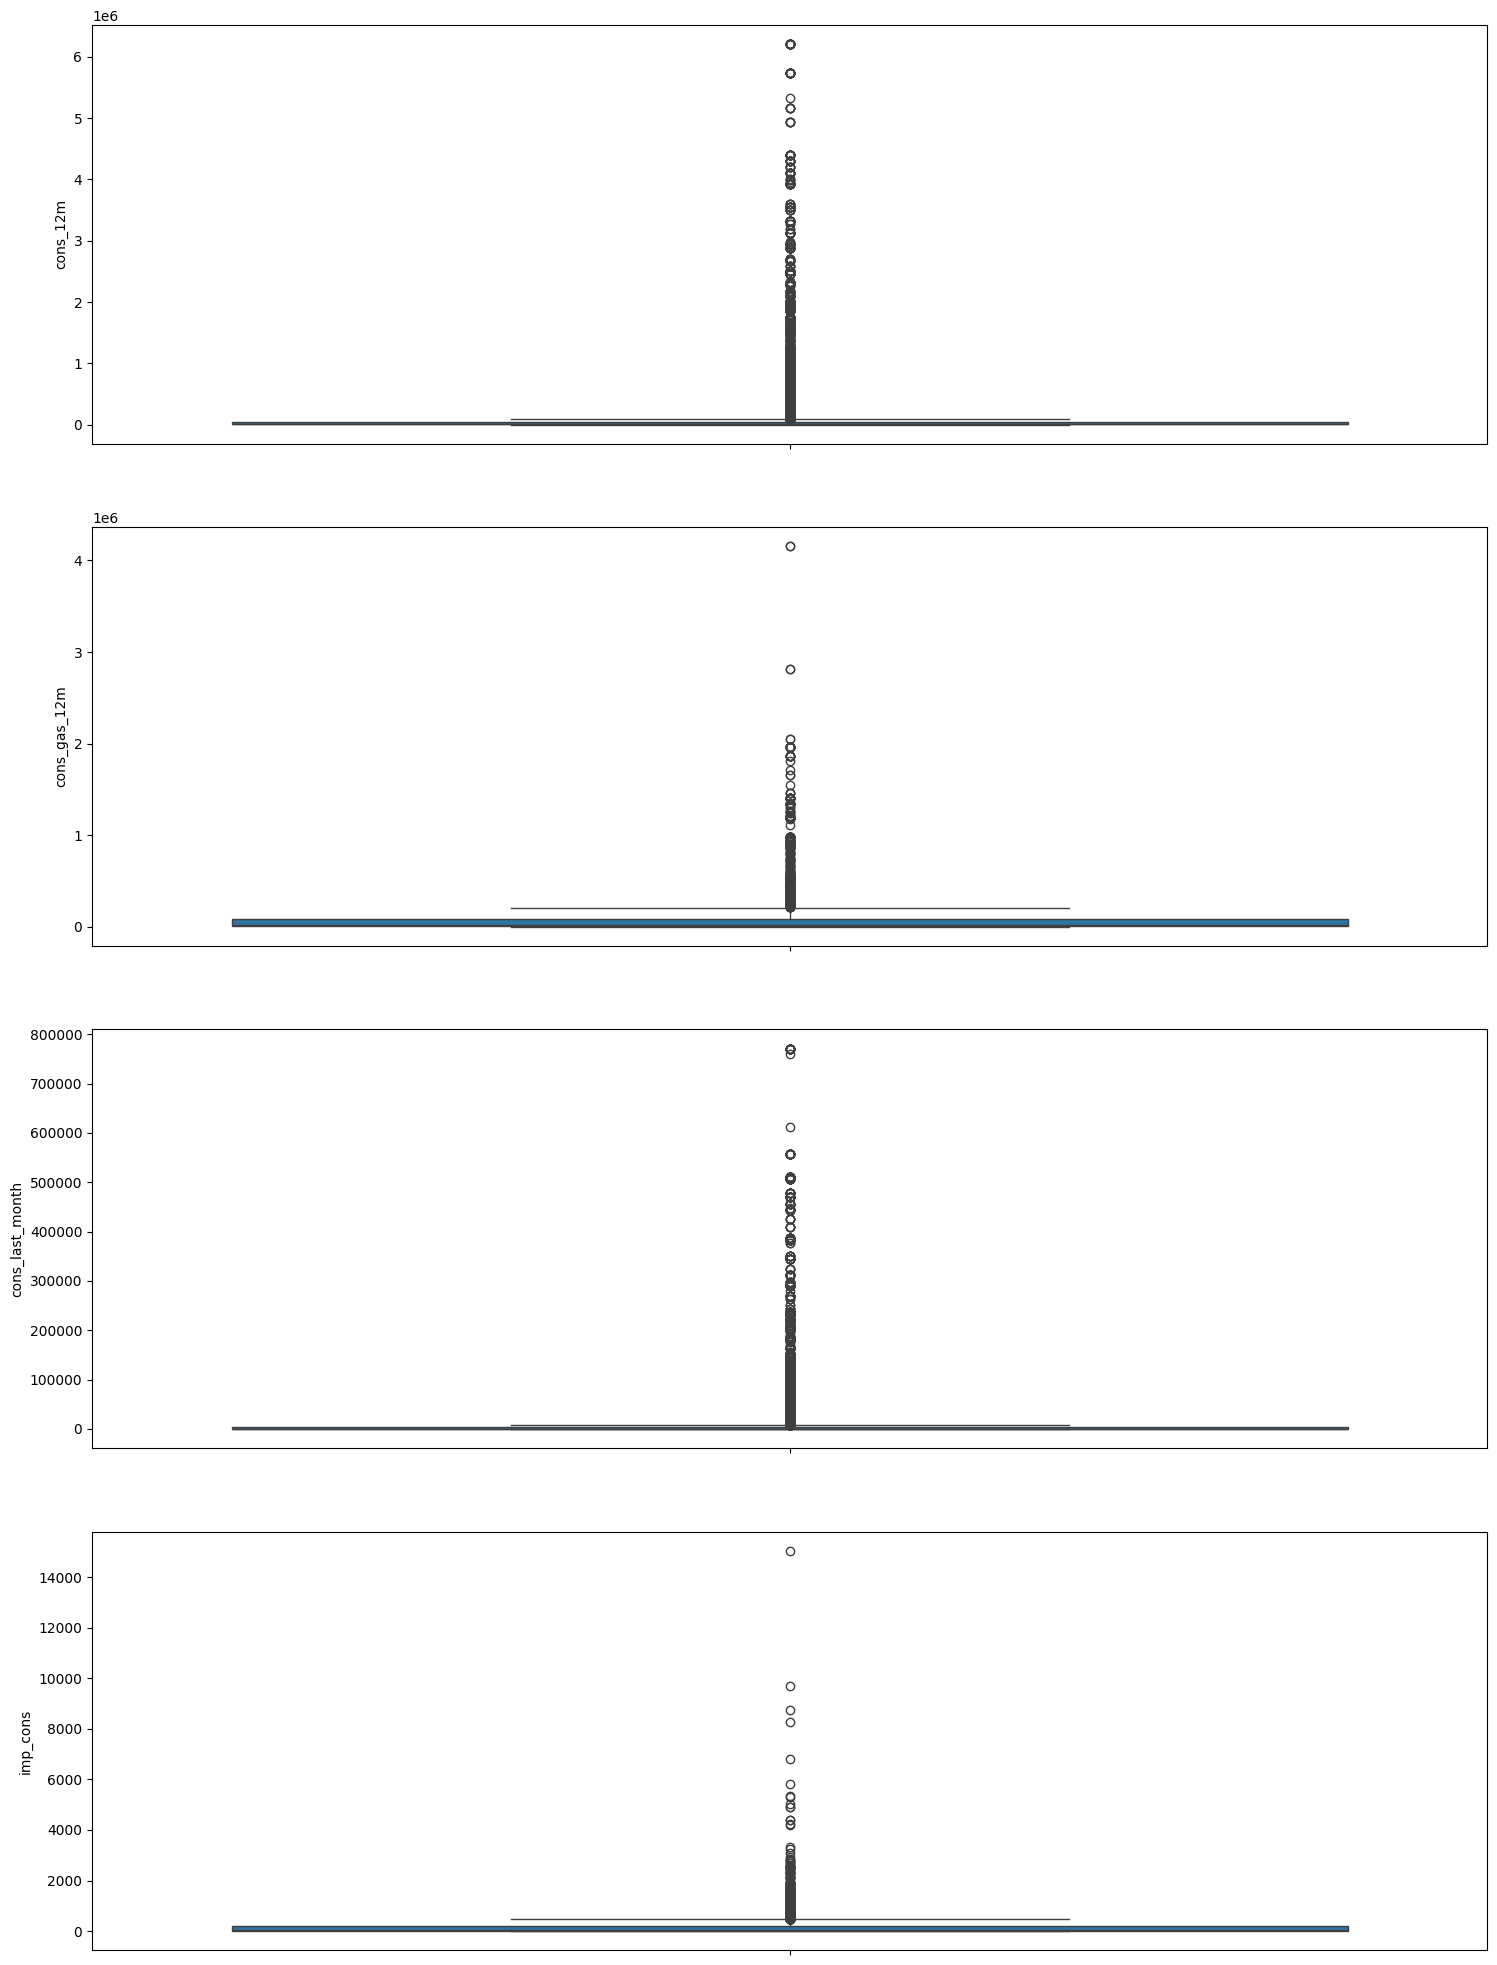

In [19]:
fig,ax=plt.subplots(nrows=4,figsize=(18,25))

sns.boxplot(consume["cons_12m"],ax=ax[0])
sns.boxplot(consume[consume["has_gas"]=="t"]["cons_gas_12m"],ax=ax[1])
sns.boxplot(consume["cons_last_month"],ax=ax[2])
sns.boxplot(consume["imp_cons"],ax=ax[3])



FORECAST

In [20]:
forecast=client[["forecast_cons_12m","forecast_cons_year",
                 "forecast_discount_energy","forecast_meter_rent_12m",
                 "forecast_price_energy_off_peak",
                 "forecast_price_energy_peak",
                 "forecast_price_pow_off_peak","churn"]]

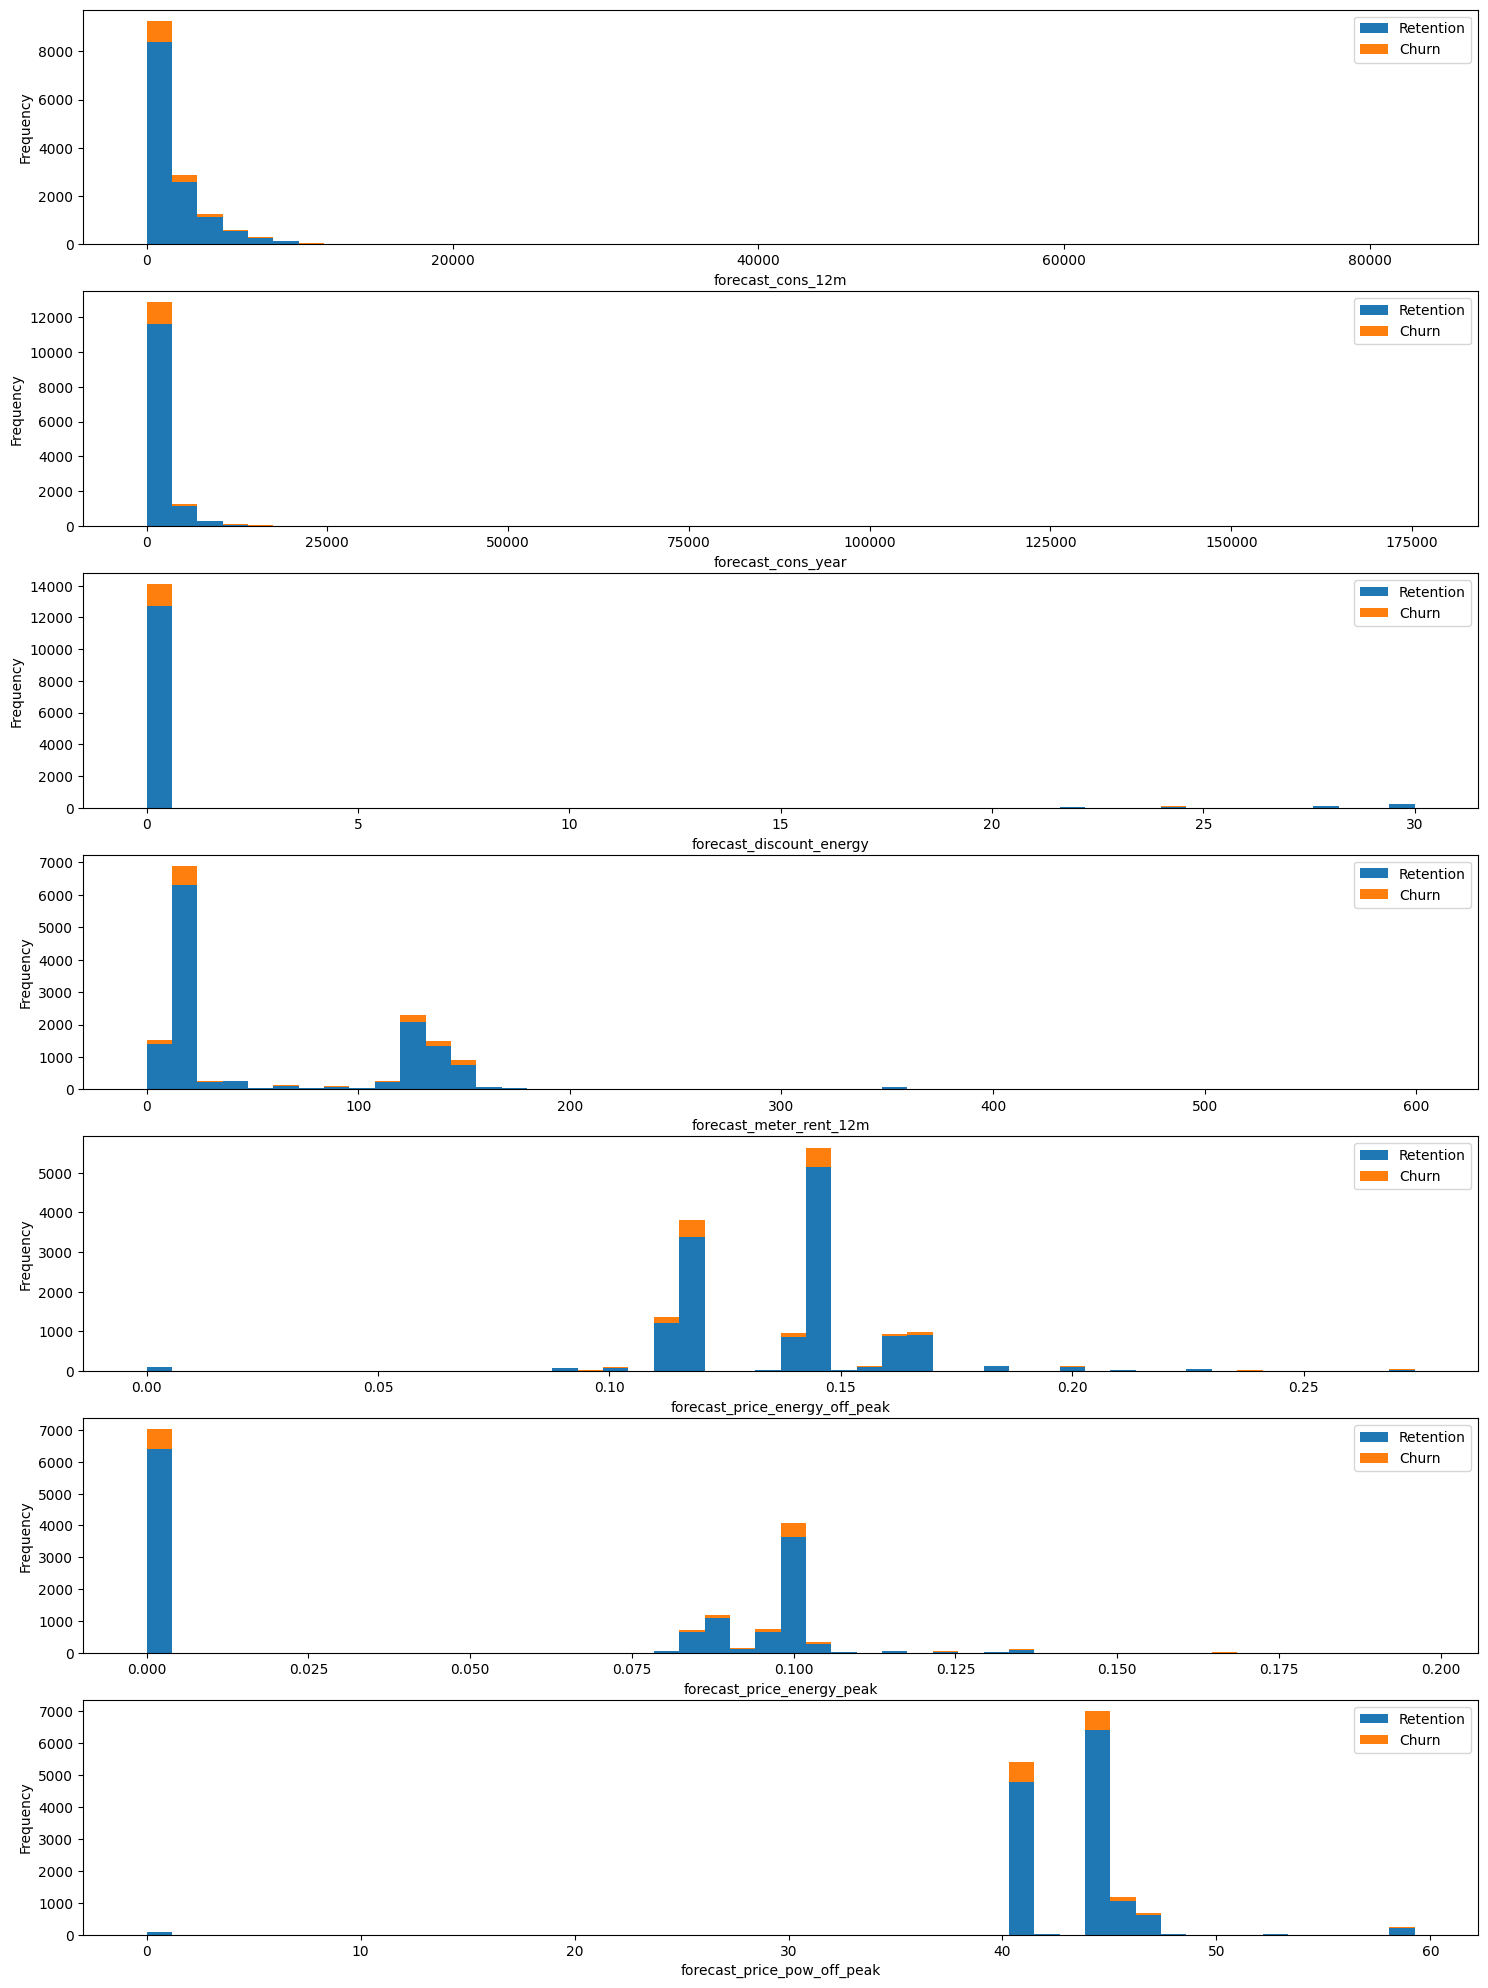

In [21]:
fig,ax=plt.subplots(nrows=7,figsize=(18,25))

hist_plot(forecast,"forecast_cons_12m",ax=ax[0])
hist_plot(forecast,"forecast_cons_year",ax=ax[1])
hist_plot(forecast,"forecast_discount_energy",ax=ax[2])
hist_plot(forecast,"forecast_meter_rent_12m",ax=ax[3])
hist_plot(forecast,"forecast_price_energy_off_peak",ax=ax[4])
hist_plot(forecast,"forecast_price_energy_peak",ax=ax[5])
hist_plot(forecast,"forecast_price_pow_off_peak",ax=ax[6])

Contract Type

In [22]:
contract=client[["id","has_gas","churn"]]
contract.columns=["company","has_gas","churn"]

contract=contract.groupby(["churn","has_gas"]).company.count()
contract=contract.unstack(level=0)
contract=contract.div(contract.sum(axis=1),axis=0)
contract

churn,0,1
has_gas,,
f,0.899456,0.100544
t,0.918144,0.081856


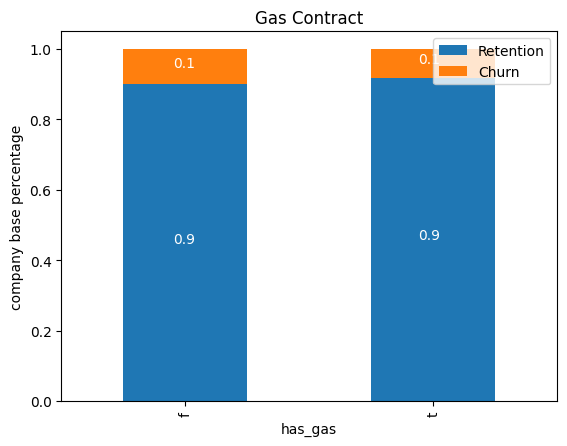

In [23]:
stack_architect(contract,"Gas Contract")

MARGIN

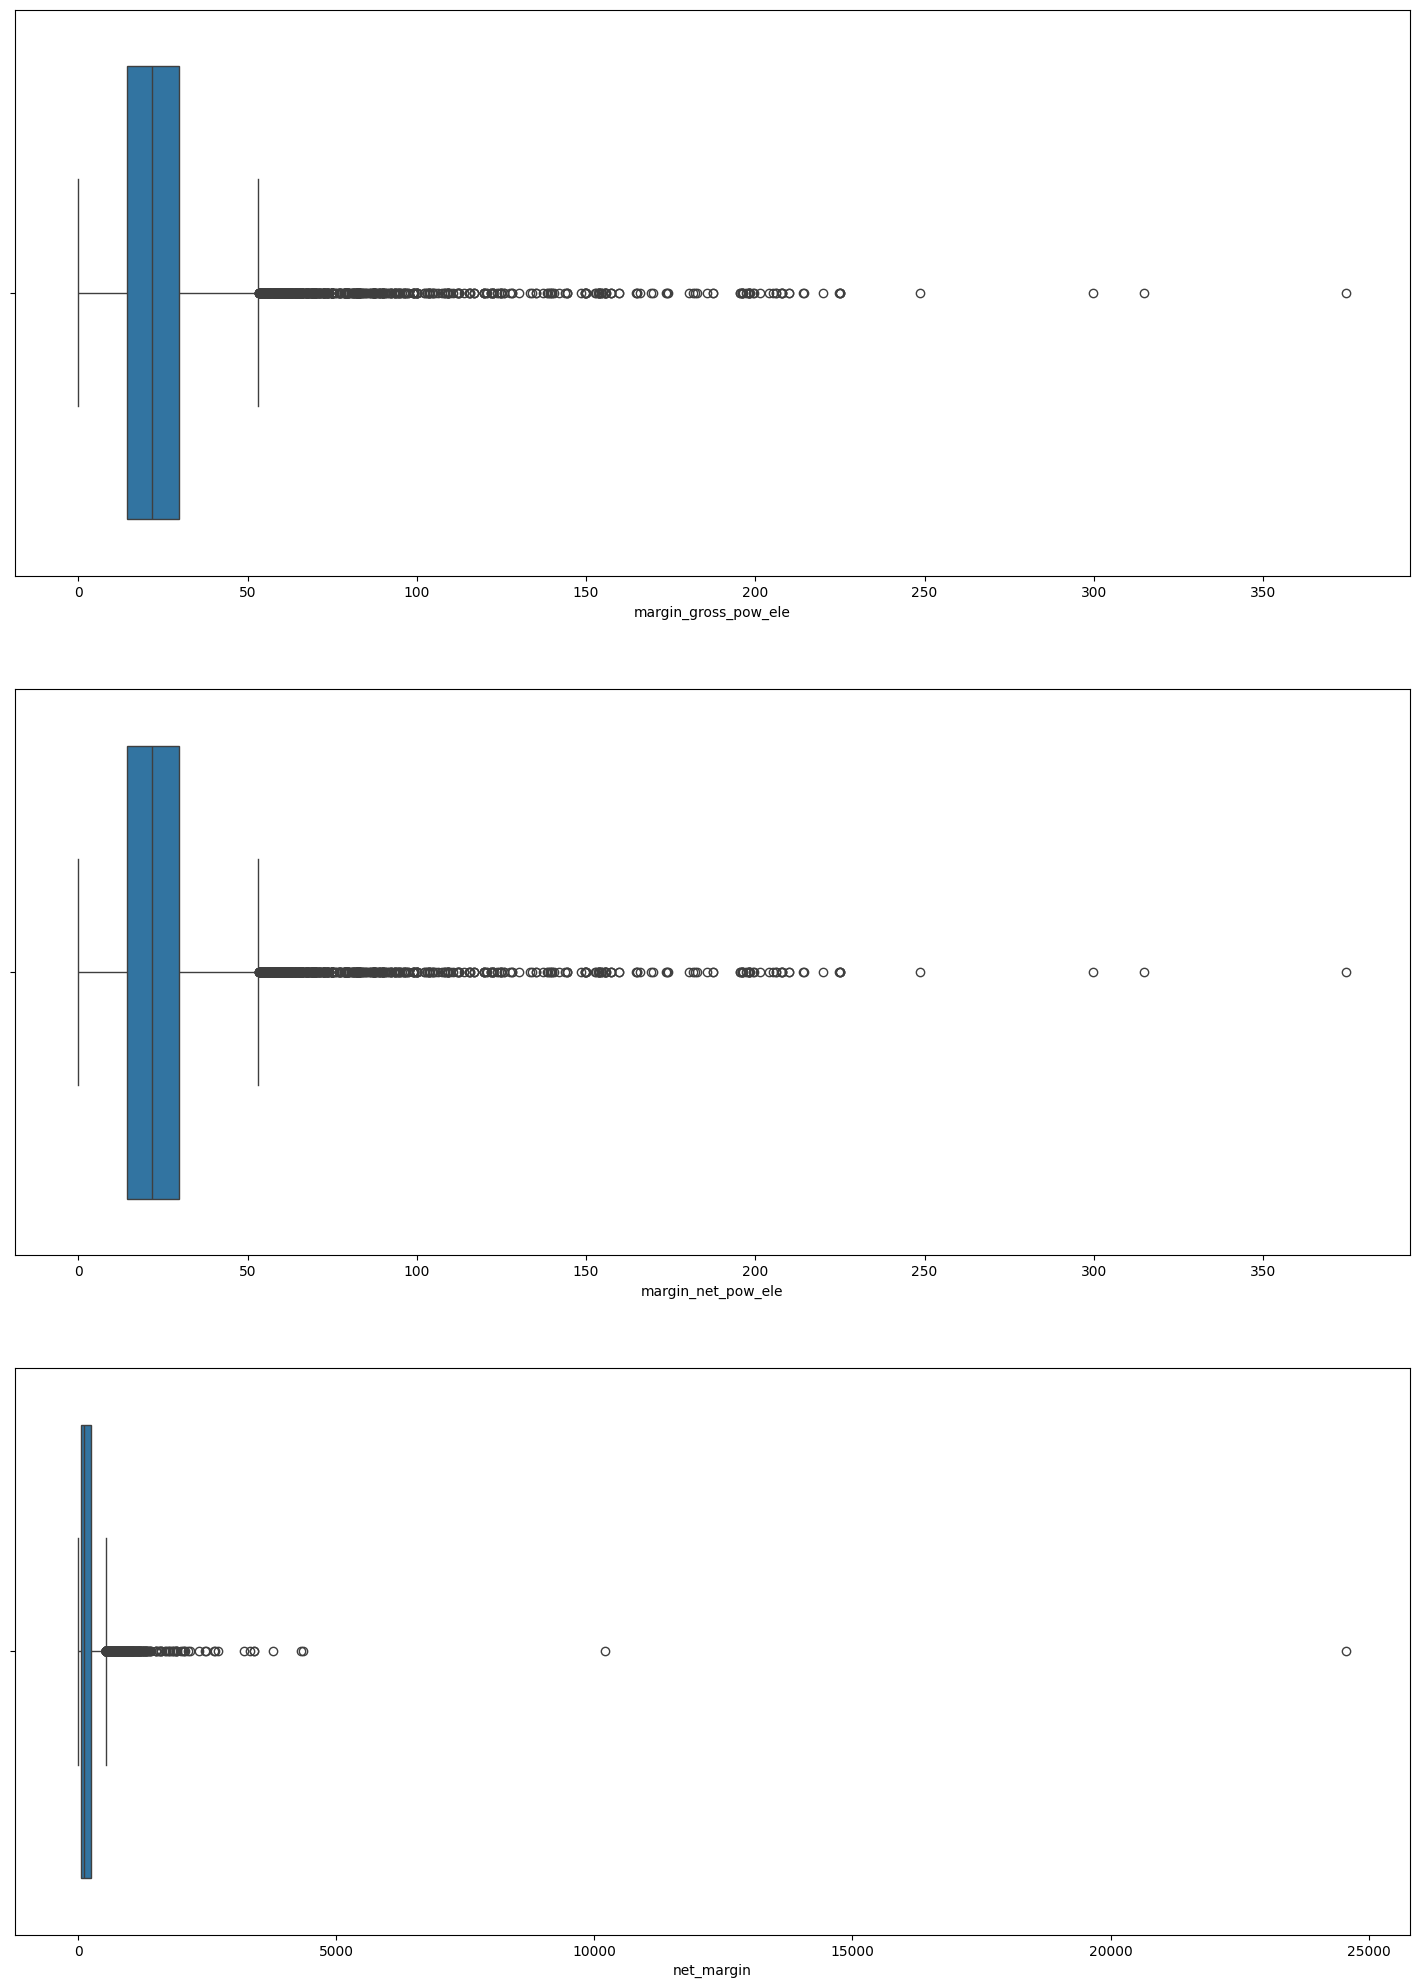

In [24]:
margin=client[["id","margin_gross_pow_ele","margin_net_pow_ele","net_margin"]]

fig,axs=plt.subplots(nrows=3,figsize=(18,25))

sns.boxplot(margin["margin_gross_pow_ele"],ax=axs[0],orient='h')
sns.boxplot(margin["margin_net_pow_ele"],ax=axs[1],orient='h')
sns.boxplot(margin["net_margin"],ax=axs[2],orient='h')

axs[0].ticklabel_format(style="plain",axis="x")
axs[1].ticklabel_format(style="plain",axis="x")
axs[2].ticklabel_format(style="plain",axis="x")

Subscribed Power

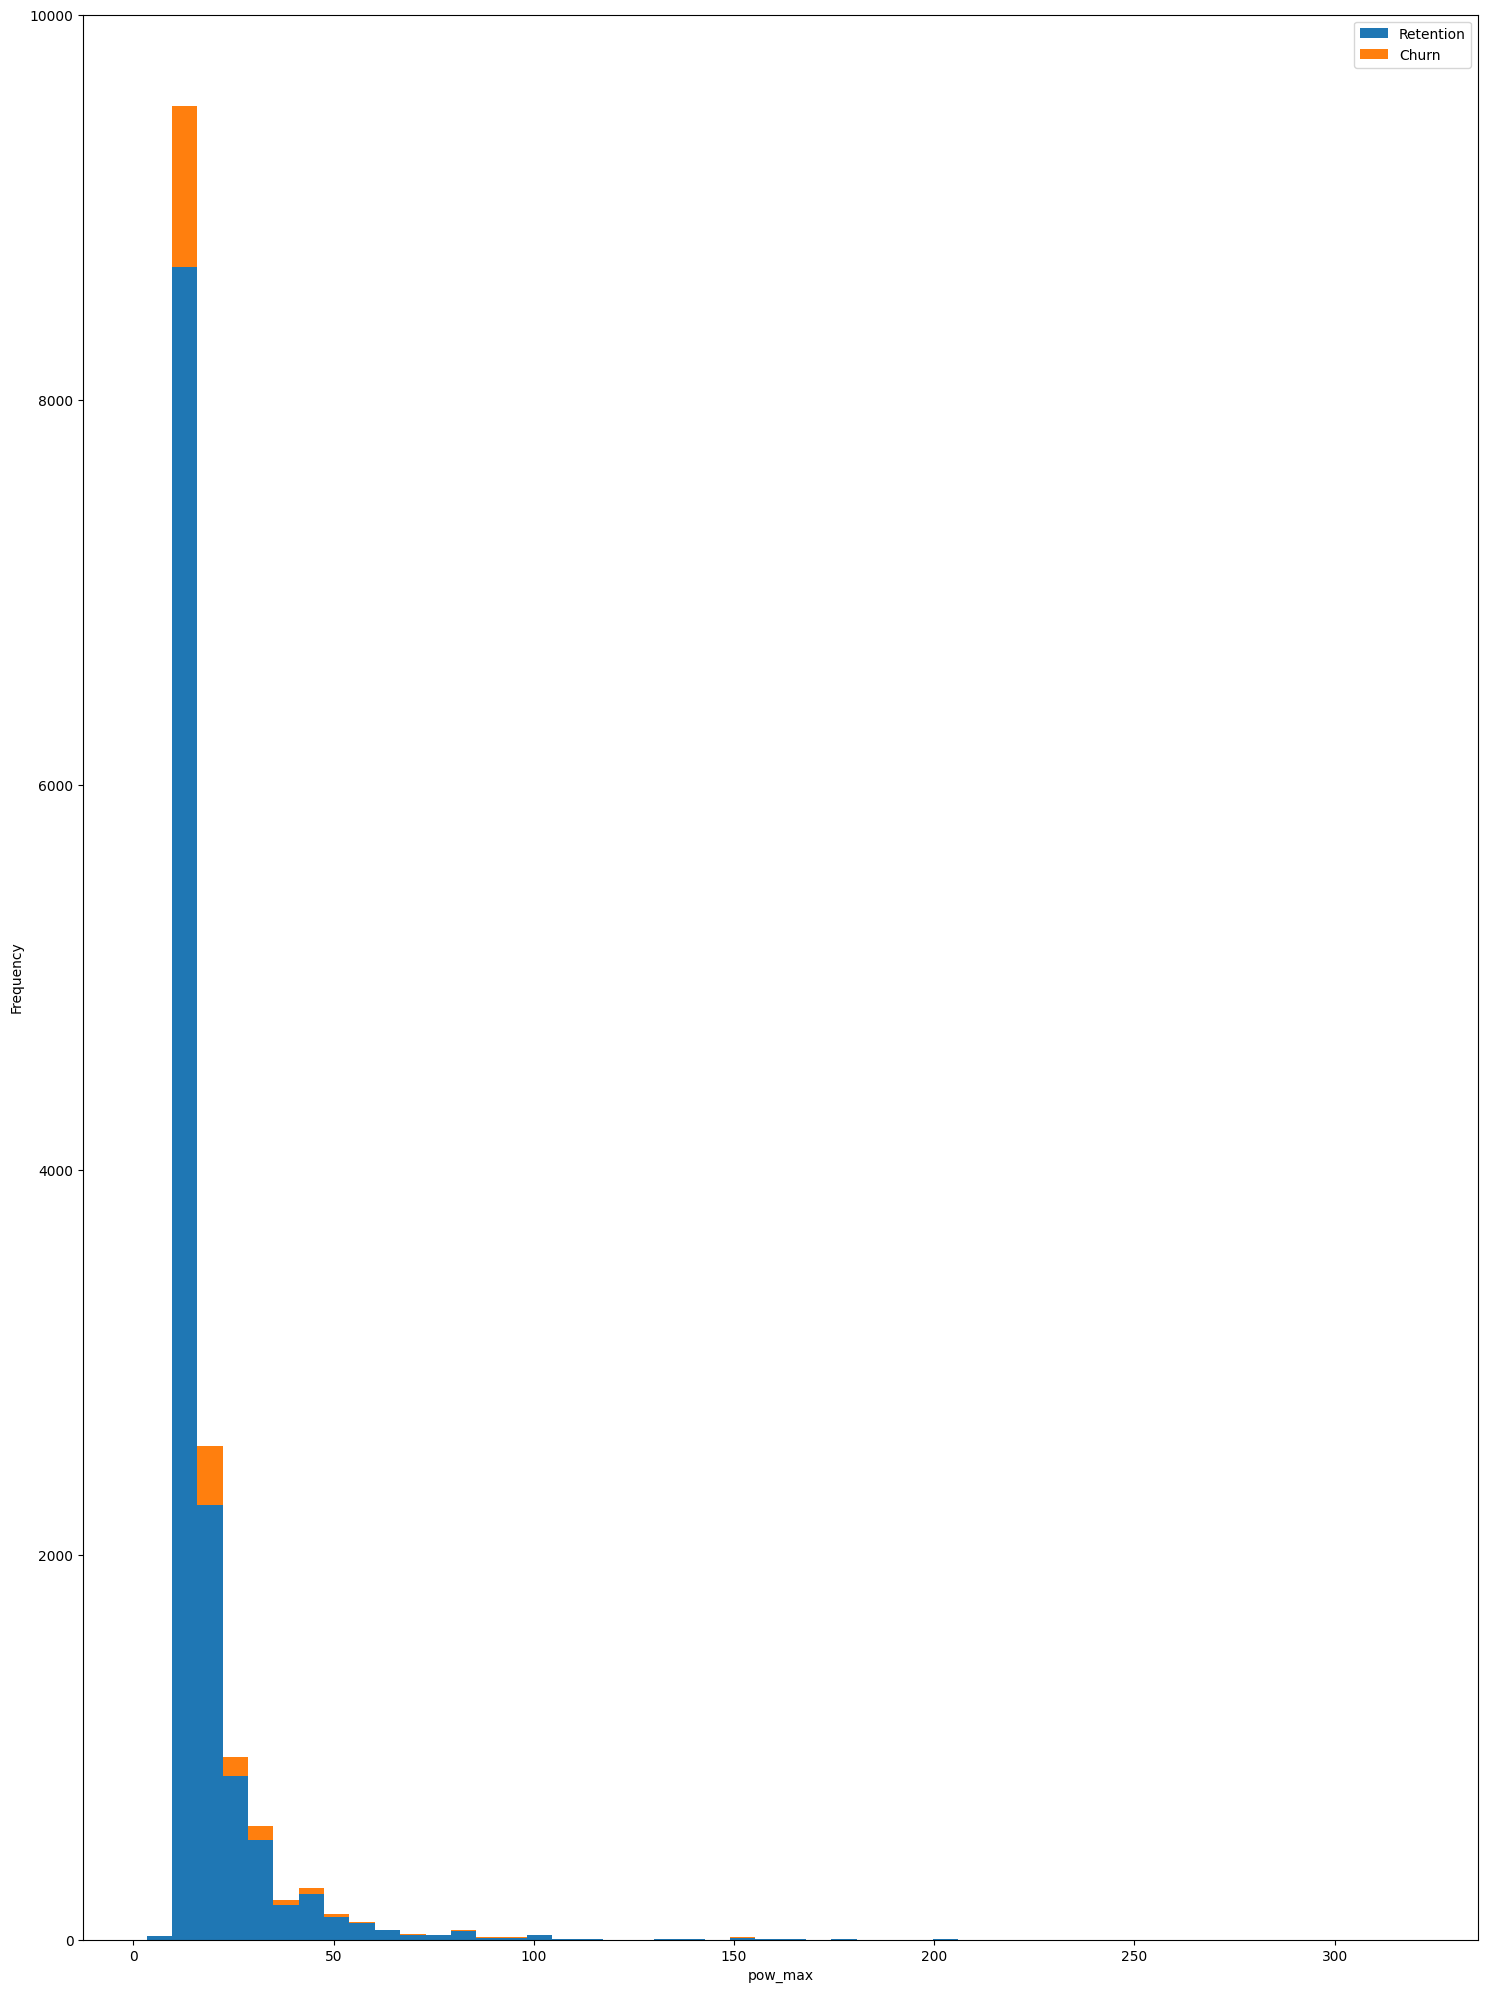

In [25]:
power=client[["id","pow_max","churn"]]

fig,ax=plt.subplots(nrows=1,figsize=(18,25))

hist_plot(power,"pow_max",ax)